In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

In [28]:
x = np.linspace(-4,4,400)

In [29]:
std_normal = stats.norm(0,1)

In [30]:
print('68-95-99.7 Rule')

print(f'P(-1<Z<1) = {std_normal.cdf(1)-std_normal.cdf(-1):.6f}')
print(f'P(-2<Z<2) = {std_normal.cdf(2)-std_normal.cdf(-2):.6f}')
print(f'P(-3<Z<3) = {std_normal.cdf(3)-std_normal.cdf(-3):.6f}')




68-95-99.7 Rule
P(-1<Z<1) = 0.682689
P(-2<Z<2) = 0.954500
P(-3<Z<3) = 0.997300


In [31]:
# Z-score standardization
mu_exam, sigma_exam = 70, 10

for score in [60, 70, 80, 90]:
    z = (score - mu_exam) / sigma_exam
    pct = std_normal.cdf(z) * 100
    print(f' Score={score}, Z={z:.2f}, Percentile={pct:.1f}%')

 Score=60, Z=-1.00, Percentile=15.9%
 Score=70, Z=0.00, Percentile=50.0%
 Score=80, Z=1.00, Percentile=84.1%
 Score=90, Z=2.00, Percentile=97.7%


In [32]:
# --- EXPONENTIAL DISTRIBUTION ---

lam = 1.0
exp_dist = stats.expon(scale=1/lam)

print(f'P(X>1) = {exp_dist.sf(1):.4f}, Var={exp_dist.var():.4f}')

# Memoryless Property
print(f'P(X>2) = {1-exp_dist.cdf(2):.4f}')
print(f'P(X>3|X>1) = {(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.4f}')

P(X>1) = 0.3679, Var=1.0000
P(X>2) = 0.1353
P(X>3|X>1) = 0.1353


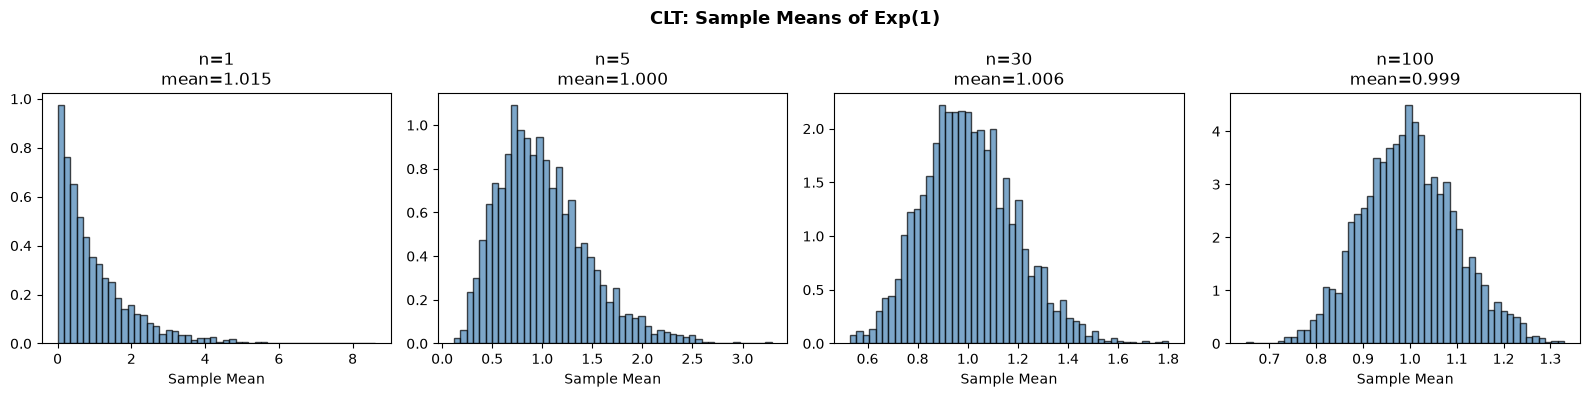

In [35]:
# --- CENTRAL LIMIT THEOREM ---

sample_sizes = (1, 5, 30, 100)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, n in enumerate(sample_sizes):
    means = [np.mean(np.random.exponential(1, n)) for _ in range(3000)]

    axes[i].hist(means, bins=50, density=True,
                 color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(f'n={n}\nmean={np.mean(means):.3f}')
    axes[i].set_xlabel('Sample Mean')

fig.suptitle('CLT: Sample Means of Exp(1)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()